In [15]:
# 1. Load required libraries
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set()
!pip install hvplot -q
import hvplot
import hvplot.pandas
from sklearn.model_selection import train_test_split
import numpy as np

In [16]:
# Source - https://stackoverflow.com/a/431715
# Posted by Michael Labbé, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-12, License - CC BY-SA 4.0

import os

os.chdir("/Users/zahrita/irish-census-project/Python/")


df = pd.read_csv("/Users/zahrita/irish-census-project/Data/dat4log2.csv")
df.head()

,countyie,age,marst,sex,lit,n,literacy_rate
0,317,72,4,1,2,88,100.0
1,301,28,4,1,2,33,100.0
2,317,73,1,1,2,31,100.0
3,308,66,1,2,2,141,100.0
4,317,73,2,1,2,166,100.0


In [17]:
# setting an objective variable 
y = df['lit']
for col in df:
    print(df['lit'].unique())


[2 1]
[2 1]
[2 1]
[2 1]
[2 1]
[2 1]
[2 1]


In [18]:
X = df[['countyie', 'age', 'sex', 'marst']]

# Exploring Explanatory Variables

In [19]:
df.describe()

,countyie,age,marst,sex,lit,n,literacy_rate
count,23587.000000,23587.000000,23587.000000,23587.000000,23587.000000,23587.000000,23587.000000
mean,316.412007,49.212193,2.212151,1.505151,1.517488,132.275660,51.748845
std,9.249333,18.524703,1.218418,0.499984,0.499705,330.320199,49.970465
min,301.000000,13.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,308.000000,34.000000,1.000000,1.000000,1.000000,13.000000,0.000000
50%,316.000000,50.000000,2.000000,2.000000,2.000000,36.000000,100.000000
75%,324.000000,65.000000,4.000000,2.000000,2.000000,108.000000,100.000000
max,332.000000,80.000000,4.000000,2.000000,2.000000,4792.000000,100.000000


In [20]:
counts = df.groupby(["age", "lit"])["n"].sum().unstack("lit")
pct = counts.div(counts.sum(axis=1), axis=0) * 100
pct.columns = ["Illiterate", "Literate"]      # assumes only lit codes 1 and 2 remain in d
pct.index = pct.index.astype(str)             # treat county codes as labels

pct.sort_values("Literate").hvplot.bar(
    stacked=True, width=900, height=400, rot=90,
    ylabel="% of people", xlabel="Age",
    ylim=(0, 100),
)

:Bars   [age,Variable]   (value)

In [21]:
counts = df.groupby(["countyie", "lit"])["n"].sum().unstack("lit")
pct = counts.div(counts.sum(axis=1), axis=0) * 100
pct.columns = ["Illiterate", "Literate"]      # assumes only lit codes 1 and 2 remain in d
pct.index = pct.index.astype(str)             # treat county codes as labels

pct.sort_values("Literate").hvplot.bar(
    stacked=True, width=900, height=400, rot=90,
    ylabel="% of people", xlabel="County code",
    ylim=(0, 100),
)

:Bars   [countyie,Variable]   (value)

In [22]:
counts = df.groupby(["sex", "lit"])["n"].sum().unstack("lit")
pct = counts.div(counts.sum(axis=1), axis=0) * 100
pct.columns = ["Illiterate", "Literate"]      # assumes only lit codes 1 and 2 remain in d
pct.index = pct.index.astype(str)             # treat county codes as labels

pct.sort_values("Literate").hvplot.bar(
    stacked=True, width=900, height=400, rot=90,
    ylabel="% of people", xlabel="Sex code",
    ylim=(0, 100),
)

:Bars   [sex,Variable]   (value)

In [23]:
counts = df.groupby(["marst", "lit"])["n"].sum().unstack("lit")
pct = counts.div(counts.sum(axis=1), axis=0) * 100
pct.columns = ["Illiterate", "Literate"]      # assumes only lit codes 1 and 2 remain in d
pct.index = pct.index.astype(str)             # treat county codes as labels

pct.sort_values("Literate").hvplot.bar(
    stacked=True, width=900, height=400, rot=90,
    ylabel="% of people", xlabel="Marital Code",
    ylim=(0, 100),
)

:Bars   [marst,Variable]   (value)

In [24]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

d = df[(df["lit"].isin([1, 2])) & (df["age"] >= 13)].copy()
d["literate"] = (d["lit"] == 2).astype(int)      # 0/1 outcome
d["age_c"] = (d["age"] - np.average(d["age"], weights=d["n"])) / 10

model = smf.glm(
    "literate ~ C(sex) + age_c + I(age_c**2) + C(marst) + C(countyie)",
    data=d,
    family=sm.families.Binomial(),
    freq_weights=d["n"],
).fit()
print(model.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:               literate   No. Observations:                23587
Model:                            GLM   Df Residuals:                  3119948
Model Family:                Binomial   Df Model:                           37
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -9.7822e+05
Date:                Mon, 12 Oct 2026   Deviance:                   1.9564e+06
Time:                        17:33:27   Pearson chi2:                 3.17e+06
No. Iterations:                    20   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              2.7520      0

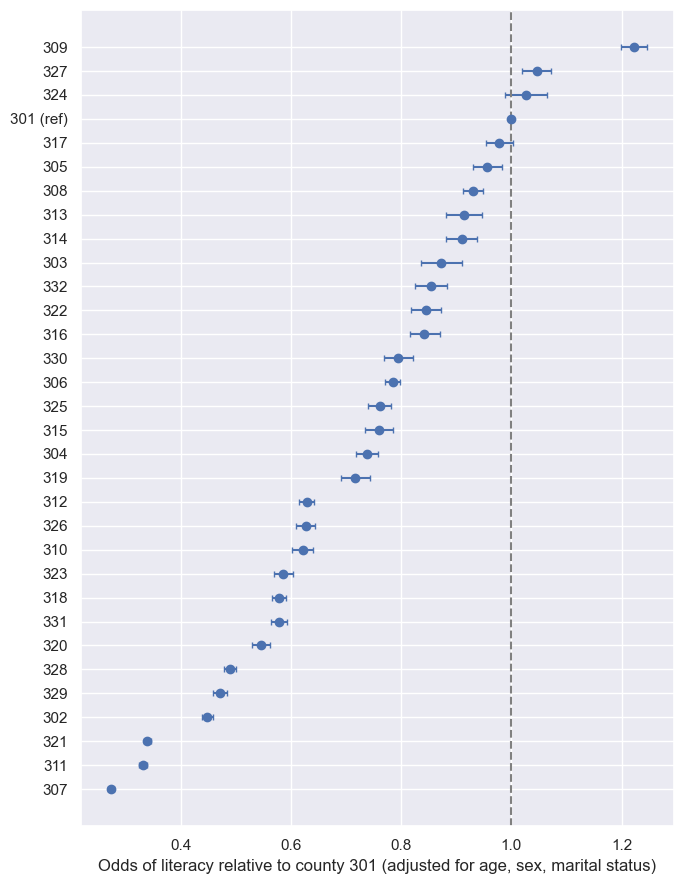

In [25]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

d = d[d["marst"] != 3].copy()                        # drop the separation category
age_mean = np.average(d["age"], weights=d["n"])
d["age_c"] = (d["age"] - age_mean) / 10
model = smf.glm("literate ~ C(sex) + age_c + I(age_c**2) + C(marst) + C(countyie)",
                data=d, family=sm.families.Binomial(), freq_weights=d["n"]).fit()

ci = model.conf_int()
tab = pd.DataFrame({"or": np.exp(model.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1])})

cty = tab.filter(like="countyie", axis=0).copy()
cty.index = cty.index.str.extract(r"\[T\.(\d+)\]", expand=False)
cty.loc["301 (ref)"] = [1, 1, 1]                      # reference county
cty = cty.sort_values("or")

fig, ax = plt.subplots(figsize=(7, 9))
y = np.arange(len(cty))
ax.errorbar(cty["or"], y, xerr=[cty["or"] - cty["lo"], cty["hi"] - cty["or"]], fmt="o", capsize=2)
ax.axvline(1, ls="--", color="grey")
ax.set_yticks(y); ax.set_yticklabels(cty.index)
ax.set_xlabel("Odds of literacy relative to county 301 (adjusted for age, sex, marital status)")
plt.tight_layout(); plt.show()

In [27]:
grid = pd.DataFrame([(a, s) for a in range(13, 81) for s in (1, 2)], columns=["age", "sex"])
grid["age_c"] = (grid["age"] - age_mean) / 10
grid["marst"] = 1
grid["countyie"] = 301                                # held fixed; change to any county

grid["p"] = model.predict(grid) * 100
grid["sex"] = grid["sex"].map({1: "Male", 2: "Female"})

import hvplot.pandas
grid.hvplot.line(x="age", y="p", by="sex", width=800, height=400,
                 ylabel="% predicted literate", xlabel="Age in 1911")

:NdOverlay   [sex]
   :Curve   [age]   (p)